In [7]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox


In [3]:
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.shape

(9994, 21)

In [13]:
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [15]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [17]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [23]:
df[['Order Date', 'Sales']].head()

,Order Date,Sales
0,11/8/2016,261.9600
1,11/8/2016,731.9400
2,6/12/2016,14.6200
3,10/11/2015,957.5775
4,10/11/2015,22.3680


In [12]:
df[['Segment', 'Sales']].head()

,Segment,Sales
0,Consumer,261.9600
1,Consumer,731.9400
2,Corporate,14.6200
3,Consumer,957.5775
4,Consumer,22.3680


In [13]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()
df['Quarter'] = df['Order Date'].dt.quarter
df['Day of Week'] = df['Order Date'].dt.day_name()

df[['Order Date', 'Year', 'Month',
    'Month Name', 'Quarter', 'Day of Week']].head()


,Order Date,Year,Month,Month Name,Quarter,Day of Week
0,2016-11-08,2016,11,November,4,Tuesday
1,2016-11-08,2016,11,November,4,Tuesday
2,2016-06-12,2016,6,June,2,Sunday
3,2015-10-11,2015,10,October,4,Sunday
4,2015-10-11,2015,10,October,4,Sunday


In [14]:
monthly_sales = (
    df.set_index('Order Date')['Sales']
      .resample('MS')
      .sum()
      .reset_index()
)

monthly_sales.columns = ['Order Date', 'Total Sales']

monthly_sales.head(10)

,Order Date,Total Sales
0,2014-01-01,14236.8950
1,2014-02-01,4519.8920
2,2014-03-01,55691.0090
3,2014-04-01,28295.3450
4,2014-05-01,23648.2870
5,2014-06-01,34595.1276
6,2014-07-01,33946.3930
7,2014-08-01,27909.4685
8,2014-09-01,81777.3508
9,2014-10-01,31453.3930


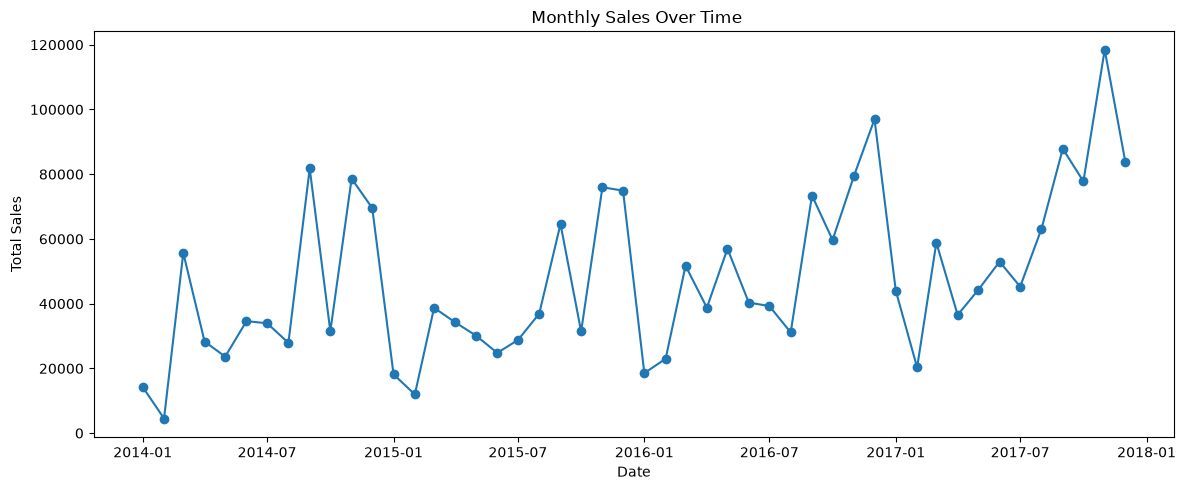

In [15]:
plt.figure(figsize=(12,5))
plt.plot(
    monthly_sales['Order Date'],
    monthly_sales['Total Sales'],
    marker='o'
)

plt.title(' Monthly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

     

In [16]:
print("Number of monthly observations:", len(monthly_sales))

Number of monthly observations: 48


In [18]:
print("\nDate range:")
print(monthly_sales['Order Date'].min(), "to",
      monthly_sales['Order Date'].max())

print("\nHighest sales month:")
print(monthly_sales.loc[
    monthly_sales['Total Sales'].idxmax()
])

print("\nLowest sales month:")
print(monthly_sales.loc[
    monthly_sales['Total Sales'].idxmin()
])


Date range:
2014-01-01 00:00:00 to 2017-12-01 00:00:00

Highest sales month:
Order Date     2017-11-01 00:00:00
Total Sales             118447.825
Name: 46, dtype: object

Lowest sales month:
Order Date     2014-02-01 00:00:00
Total Sales               4519.892
Name: 1, dtype: object


In [19]:
print("Original 80/20 experiment: Linear Regression and Holt-Winters use a chronological train/test split.")

forecast_df = monthly_sales.copy()
forecast_df['Month_Number'] = np.arange(1, len(forecast_df) + 1)

X = forecast_df[['Month_Number']]
y = forecast_df['Total Sales']
forecast_df.head()

print("Original 80/20 experiment: Linear Regression and Holt-Winters use a chronological train/test split.")


,Order Date,Total Sales,Month_Number
0,2014-01-01,14236.895,1
1,2014-02-01,4519.892,2
2,2014-03-01,55691.009,3
3,2014-04-01,28295.345,4
4,2014-05-01,23648.287,5


In [20]:
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

model = LinearRegression()
model.fit(X_train, y_train)

models_dir_candidates = [
    Path.cwd() / "Sample-Superstore" / "models",
    Path.cwd() / "models",
    Path.cwd().parent / "models",
    Path.cwd() / "SuperStore" / "Sample-Superstore" / "models",
]
models_dir = next(path for path in models_dir_candidates if path.is_dir())
joblib.dump(model, models_dir / "linear_regression_model.pkl")
print("Saved Linear Regression model:", models_dir / "linear_regression_model.pkl")
y_pred = model.predict(X_test)

y_pred[:5]

Saved Linear Regression model: c:\Users\netsh\OneDrive\Documentos\Moose CODES\FUTURE_ML_01\SuperStore\Sample-Superstore\models\linear_regression_model.pkl


array([56490.0565559 , 57189.60316403, 57889.14977216, 58588.69638029,
       59288.24298842])

In [14]:
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 38
Testing observations: 10


In [21]:
# Forecasting the next 6 month
future_months = pd.DataFrame({
    'Month_Number': np.arange(
        len(forecast_df) + 1,
        len(forecast_df) + 7
    )
})
future_sales = model.predict(future_months)
last_date = forecast_df['Order Date'].max()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=6,
    freq='MS'
)
future_forecast = pd.DataFrame({'Order Date': future_dates, 'Forecast Sales': future_sales})
future_forecast = pd.DataFrame({'Order Date': future_dates, 'Forecast Sales': future_sales})
display(future_forecast)

,Order Date,Forecast Sales
0,2018-01-01,63485.522637
1,2018-02-01,64185.069245
2,2018-03-01,64884.615853
3,2018-04-01,65584.162462
4,2018-05-01,66283.709070
5,2018-06-01,66983.255678


In [22]:
#Evaluation Metrics

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100


print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")


MAE:  18041.64
RMSE: 23416.38
MAPE: 26.26%


In [23]:
comparison = pd.DataFrame({
    'Date': forecast_df['Order Date'].iloc[split_index:],
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

comparison['Absolute Error'] = abs(
    comparison['Actual Sales'] - comparison['Predicted Sales']
)

display(comparison.round(2))

C:\Users\netsh\AppData\Local\Temp\ipykernel_18380\2486402890.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparison.round(2))


,Date,Actual Sales,Predicted Sales,Absolute Error
38,2017-03-01,58872.35,56490.06,2382.30
39,2017-04-01,36521.54,57189.60,20668.07
40,2017-05-01,44261.11,57889.15,13628.04
41,2017-06-01,52981.73,58588.70,5606.97
42,2017-07-01,45264.42,59288.24,14023.83
43,2017-08-01,63120.89,59987.79,3133.10
44,2017-09-01,87866.65,60687.34,27179.32
45,2017-10-01,77776.92,61386.88,16390.04
46,2017-11-01,118447.82,62086.43,56361.40
47,2017-12-01,83829.32,62785.98,21043.34


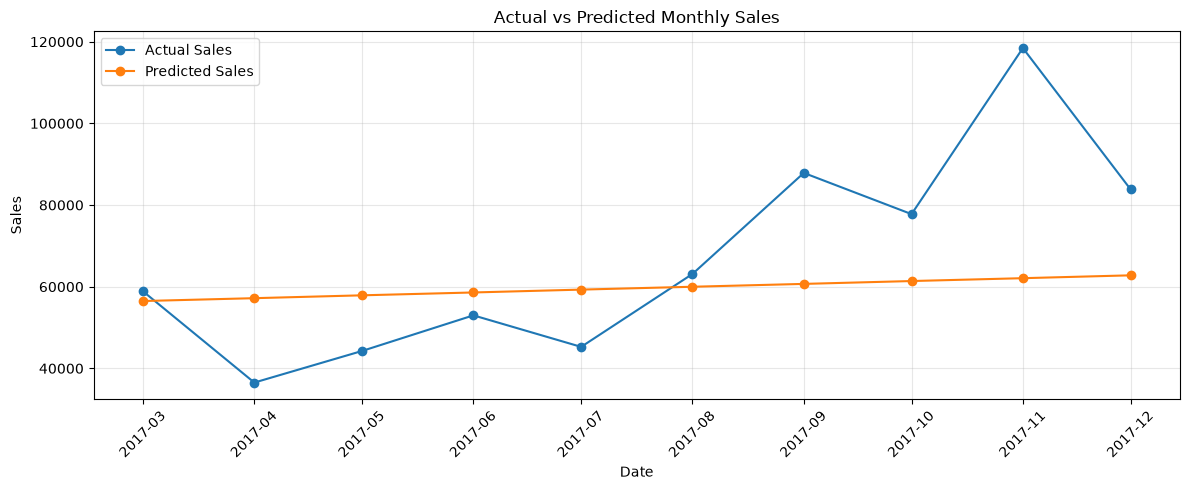

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    comparison['Date'],
    comparison['Actual Sales'],
    marker='o',
    label='Actual Sales'
)

plt.plot(
    comparison['Date'],
    comparison['Predicted Sales'],
    marker='o',
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Monthly Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

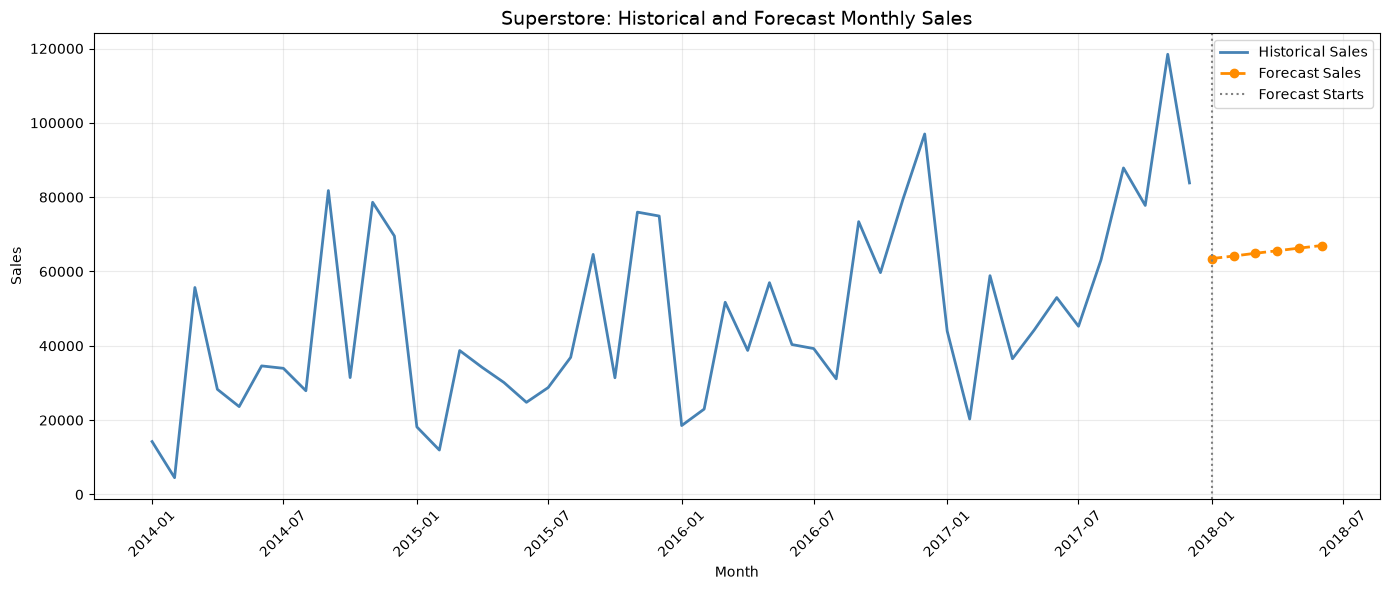

In [19]:
plt.figure(figsize=(14, 6))

# Historical monthly sales
plt.plot(
    monthly_sales['Order Date'],
    monthly_sales['Total Sales'],
    label='Historical Sales',
    color='steelblue',
    linewidth=2
)

# Six-month future forecast
plt.plot(
    future_forecast['Order Date'],
    future_forecast['Forecast Sales'],
    label='Forecast Sales',
    color='darkorange',
    marker='o',
    linestyle='--',
    linewidth=2
)

plt.axvline(
    x=future_forecast['Order Date'].min(),
    color='gray',
    linestyle=':',
    label='Forecast Starts'
)

plt.title(
    'Superstore: Historical and Forecast Monthly Sales',
    fontsize=14
)
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True, alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:

train_sales = monthly_sales["Total Sales"].iloc[:split_index]
test_sales = monthly_sales["Total Sales"].iloc[split_index:]

model_hw = ExponentialSmoothing(
    train_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

joblib.dump(model_hw, models_dir / "holt_winters_model.pkl")
print("Saved Holt-Winters model:", models_dir / "holt_winters_model.pkl")

predictions_hw = model_hw.forecast(len(test_sales))

mae_hw = mean_absolute_error(test_sales, predictions_hw)
rmse_hw = np.sqrt(mean_squared_error(test_sales, predictions_hw))
mape_hw = np.mean(np.abs((test_sales - predictions_hw) / test_sales)) * 100

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Linear Regression": [mae, rmse, mape],
    "Holt-Winters": [mae_hw, rmse_hw, mape_hw]
})

display(results.round(2))

Saved Holt-Winters model: c:\Users\netsh\OneDrive\Documentos\Moose CODES\FUTURE_ML_01\SuperStore\Sample-Superstore\models\holt_winters_model.pkl


,Metric,Linear Regression,Holt-Winters
0,MAE,18041.64,11427.54
1,RMSE,23416.38,12647.99
2,MAPE,26.26,18.75


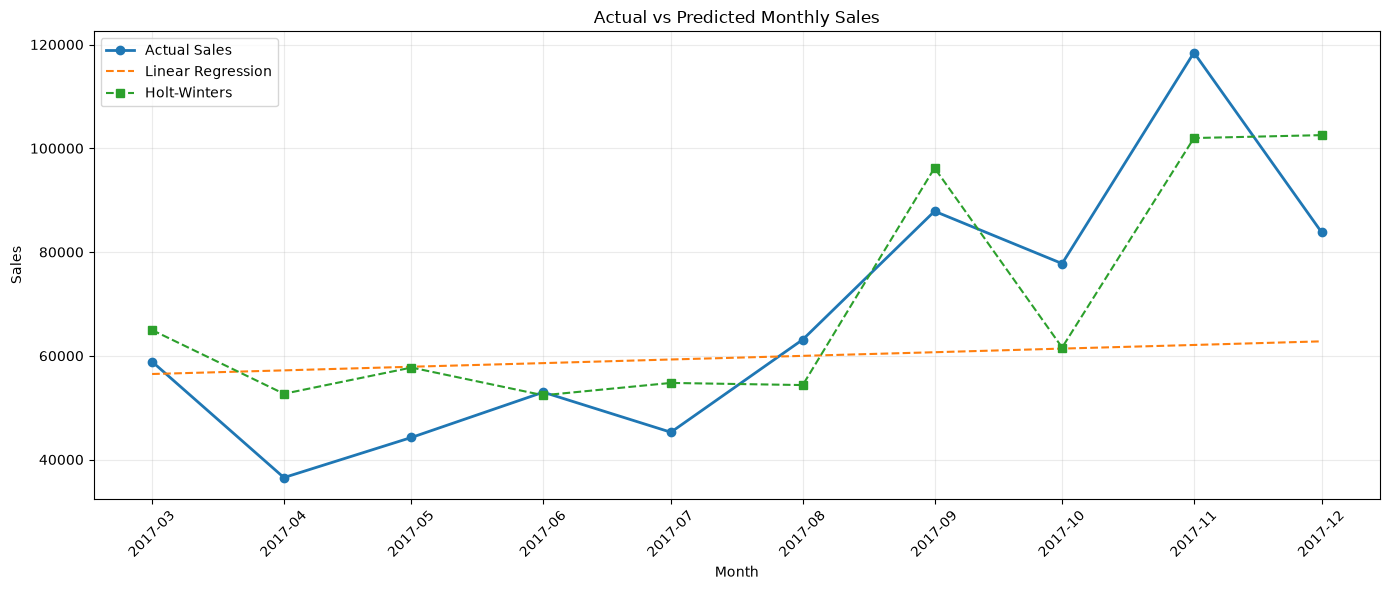

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_sales.index.map(lambda i: monthly_sales.loc[i, "Order Date"]),
    test_sales.values,
    label="Actual Sales",
    marker="o",
    linewidth=2
)

plt.plot(
    monthly_sales["Order Date"].iloc[split_index:],
    y_pred,
    label="Linear Regression",
    linestyle="--"
)

plt.plot(
    monthly_sales["Order Date"].iloc[split_index:],
    predictions_hw.values,
    label="Holt-Winters",
    linestyle="--",
    marker="s"
)

plt.title("Actual vs Predicted Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
final_model = ExponentialSmoothing(
    monthly_sales["Total Sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)
joblib.dump(final_model, models_dir / "holt_winters_model.pkl")

future_dates = pd.date_range(
    start=monthly_sales["Order Date"].max() + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

forecast_values = final_model.forecast(6)

final_forecast = pd.DataFrame({
    "Month": future_dates,
    "Forecast Sales": forecast_values.values
})

final_forecast["Forecast Sales"] = final_forecast["Forecast Sales"].round(2)

forecast_horizons = np.arange(1, len(final_forecast) + 1)
forecast_margin = 1.96 * rmse_hw * np.sqrt(forecast_horizons)
final_forecast["Lower 95%"] = np.maximum(
    0, final_forecast["Forecast Sales"] - forecast_margin
).round(2)
final_forecast["Upper 95%"] = (
    final_forecast["Forecast Sales"] + forecast_margin
).round(2)

display(final_forecast)

,Month,Forecast Sales,Lower 95%,Upper 95%
0,2018-01-01,49688.61,24898.56,74478.66
1,2018-02-01,41837.75,6779.32,76896.18
2,2018-03-01,74878.98,31941.35,117816.61
3,2018-04-01,61538.17,11958.06,111118.28
4,2018-05-01,68504.07,13071.82,123936.32
5,2018-06-01,65401.34,4678.36,126124.32


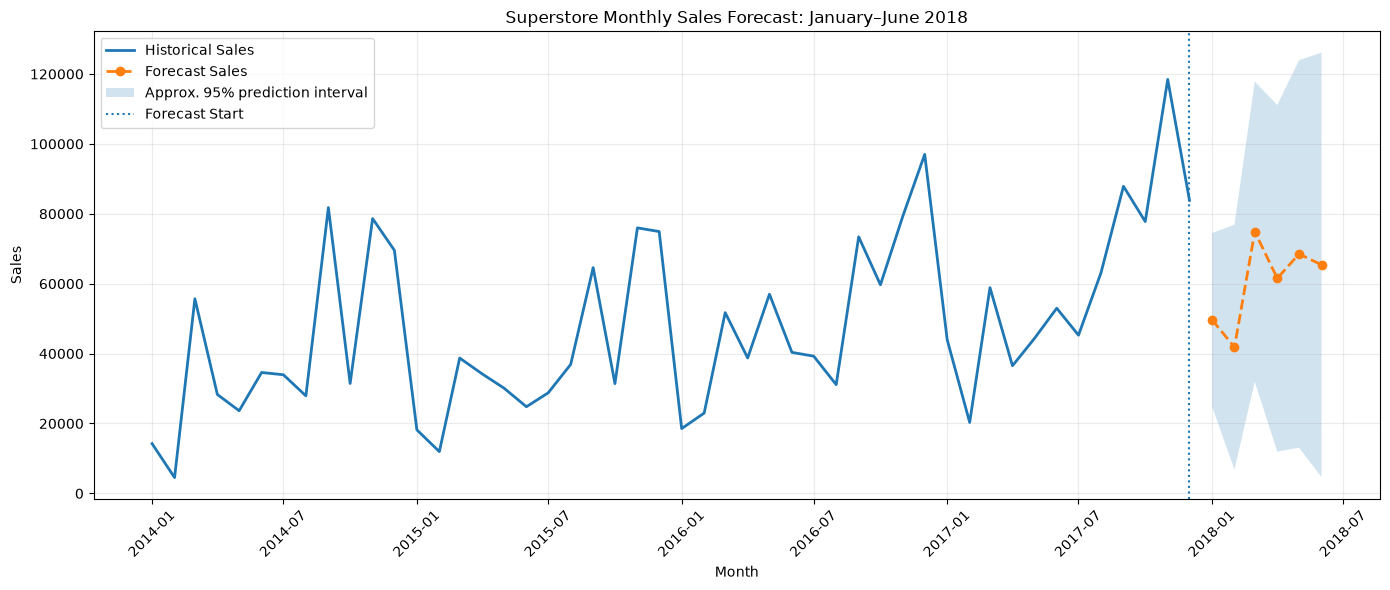

            Model                                      Forecast approach
Linear Regression                           Projects a linear time trend
     Holt-Winters                    Models trend and annual seasonality
   Seasonal Naive Repeats sales from the same month in the previous year
           SARIMA        Models non-seasonal and seasonal ARIMA patterns

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Total Sales"],
    label="Historical Sales",
    linewidth=2
)

plt.plot(
    final_forecast["Month"],
    final_forecast["Forecast Sales"],
    label="Forecast Sales",
    linestyle="--",
    marker="o",
    linewidth=2
)

plt.fill_between(
    final_forecast["Month"],
    final_forecast["Lower 95%"],
    final_forecast["Upper 95%"],
    alpha=0.2,
    label="Approx. 95% prediction interval"
)

plt.axvline(
    x=monthly_sales["Order Date"].max(),
    linestyle=":",
    label="Forecast Start"
)

plt.title(
    "Superstore Monthly Sales Forecast: "
    f"{final_forecast['Month'].min():%B %Y}–{final_forecast['Month'].max():%B %Y}"
)
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

walk_forward_model_overview = pd.DataFrame({
    "Model": ["Linear Regression", "Holt-Winters", "Seasonal Naive", "SARIMA"],
    "Forecast approach": [
        "Projects a linear time trend",
        "Models trend and annual seasonality",
        "Repeats sales from the same month in the previous year",
        "Models non-seasonal and seasonal ARIMA patterns",
    ],
})
display(walk_forward_model_overview)

seasonal_naive_model = {
    "seasonal_period": 12,
    "last_season": monthly_sales["Total Sales"].iloc[-12:].to_numpy(),
}
joblib.dump(seasonal_naive_model, models_dir / "seasonal_naive_model.pkl")


In [26]:
initial_train_size = 24
forecast_horizon = 3
sarima_configs = [
    {"order": (1, 1, 1), "seasonal_order": (1, 1, 1, 12)},
    {"order": (1, 1, 0), "seasonal_order": (1, 1, 1, 12)},
    {"order": (0, 1, 1), "seasonal_order": (1, 1, 1, 12)},
    {"order": (1, 1, 1), "seasonal_order": (0, 1, 1, 12)},
]

sales = monthly_sales["Total Sales"].reset_index(drop=True).astype(float)
validation_folds = list(range(
    initial_train_size,
    len(sales) - forecast_horizon + 1,
    forecast_horizon,
))

print(f"Monthly observations: {len(sales)}")
print(f"Validation folds: {len(validation_folds)}")
print(f"Initial training window: {initial_train_size} months")
print(f"Forecast horizon per fold: {forecast_horizon} months")


Monthly observations: 48
Validation folds: 8
Initial training window: 24 months
Forecast horizon per fold: 3 months


In [27]:
if len(sales) < initial_train_size + forecast_horizon:
    raise ValueError("At least 27 monthly observations are required for walk-forward validation.")

actual_values = []
linear_values = []
holt_winters_values = []
seasonal_naive_values = []
validation_months = []
sarima_predictions = {str(config): [] for config in sarima_configs}
sarima_failures = {str(config): 0 for config in sarima_configs}
sarima_parameter_records = []

for fold_number, split_index in enumerate(validation_folds, start=1):
    train = sales.iloc[:split_index]
    test = sales.iloc[split_index:split_index + forecast_horizon]

    train_time = np.arange(len(train)).reshape(-1, 1)
    test_time = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)
    linear_model_walk = LinearRegression().fit(train_time, train.to_numpy())
    linear_fold_prediction = linear_model_walk.predict(test_time)

    hw_model_walk = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated",
    ).fit()
    hw_fold_prediction = np.asarray(hw_model_walk.forecast(len(test)))

    seasonal_fold_prediction = train.iloc[-12:-12 + len(test)].to_numpy()

    actual_values.extend(test.to_list())
    linear_values.extend(linear_fold_prediction.tolist())
    holt_winters_values.extend(hw_fold_prediction.tolist())
    seasonal_naive_values.extend(seasonal_fold_prediction.tolist())
    validation_months.extend(monthly_sales["Order Date"].iloc[split_index:split_index + len(test)].tolist())

    for config in sarima_configs:
        config_key = str(config)
        warning_messages = []
        warning_categories = []

        def record_and_show_warning(message, category, filename, lineno, file=None, line=None):
            warning_messages.append(str(message))
            warning_categories.append(category.__name__)
            previous_showwarning(message, category, filename, lineno, file=file, line=line)

        fit_status = "Failed"
        converged = np.nan
        iterations = np.nan
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("always")
                previous_showwarning = warnings.showwarning
                warnings.showwarning = record_and_show_warning
                sarima_model_walk = SARIMAX(
                    train,
                    order=config["order"],
                    seasonal_order=config["seasonal_order"],
                    enforce_stationarity=False,
                    enforce_invertibility=False,
                ).fit(disp=False, maxiter=200)

            fit_details = sarima_model_walk.mle_retvals
            converged = fit_details.get("converged", np.nan)
            iterations = fit_details.get("iterations", np.nan)
            fold_prediction = np.asarray(sarima_model_walk.forecast(len(test)), dtype=float)

            if len(fold_prediction) != len(test) or not np.isfinite(fold_prediction).all():
                raise ValueError("Forecast length was incorrect or forecast contained non-finite values.")

            fit_status = "Successful"
            sarima_predictions[config_key].extend(fold_prediction.tolist())
            parameter_names = sarima_model_walk.param_names
            parameter_estimates = np.asarray(sarima_model_walk.params, dtype=float)
            parameter_standard_errors = np.asarray(sarima_model_walk.bse, dtype=float)
            for parameter_name, estimate, standard_error in zip(
                parameter_names, parameter_estimates, parameter_standard_errors
            ):
                sarima_parameter_records.append({
                    "Fold": fold_number,
                    "Training months": len(train),
                    "Configuration": config_key,
                    "Parameter": parameter_name,
                    "Estimate": estimate,
                    "Standard error": standard_error,
                    "Converged": converged,
                    "Iterations": iterations,
                    "Fit status": fit_status,
                    "Warning categories": "; ".join(warning_categories),
                    "Warnings": " | ".join(warning_messages),
                    "Failure": "",
                })
        except Exception as error:
            sarima_predictions[config_key].extend([np.nan] * len(test))
            sarima_failures[config_key] += 1
            sarima_parameter_records.append({
                "Fold": fold_number,
                "Training months": len(train),
                "Configuration": config_key,
                "Parameter": "Fit",
                "Estimate": np.nan,
                "Standard error": np.nan,
                "Converged": converged,
                "Iterations": iterations,
                "Fit status": fit_status,
                "Warning categories": "; ".join(warning_categories),
                "Warnings": " | ".join(warning_messages),
                "Failure": f"{type(error).__name__}: {error}",
            })

actual_values = np.asarray(actual_values, dtype=float)
if len(actual_values) == 0:
    raise ValueError("No walk-forward validation folds were produced.")


c:\Users\netsh\OneDrive\Documentos\Moose CODES\FUTURE_ML_01\SuperStore\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
c:\Users\netsh\OneDrive\Documentos\Moose CODES\FUTURE_ML_01\SuperStore\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
c:\Users\netsh\OneDrive\Documentos\Moose CODES\FUTURE_ML_01\SuperStore\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
c:\Users\netsh\OneDrive\Documentos\Mo

In [28]:
sarima_parameter_stability = pd.DataFrame(sarima_parameter_records)

if sarima_parameter_stability.empty:
    raise ValueError("No SARIMA fit diagnostics were recorded.")

parameter_rows = sarima_parameter_stability[
    sarima_parameter_stability["Parameter"] != "Fit"
].copy()

parameter_rows["Non-finite SE"] = ~np.isfinite(parameter_rows["Standard error"])
parameter_rows["Large SE"] = (
    parameter_rows["Standard error"] >= parameter_rows["Estimate"].abs()
) & np.isfinite(parameter_rows["Standard error"])

parameter_rows["Boundary warning"] = parameter_rows.apply(
    lambda row: (
        "Outside" if abs(row["Estimate"]) > 1 else
        "Near" if abs(row["Estimate"]) >= 0.95 else
        "No"
    ) if np.isfinite(row["Estimate"]) and
    ("ar." in row["Parameter"].lower() or "ma." in row["Parameter"].lower())
    else "No",
    axis=1
)

parameter_rows["Numerical warning"] = parameter_rows["Warning categories"].fillna("").str.contains(
    "RuntimeWarning", case=False
)

parameter_rows["Unstable"] = (
    parameter_rows["Non-finite SE"]
    | parameter_rows["Large SE"]
    | parameter_rows["Boundary warning"].ne("No")
    | parameter_rows["Numerical warning"]
)

parameter_rows["Configuration"] = parameter_rows["Configuration"].map({
    str(config): f"SARIMA {i + 1}"
    for i, config in enumerate(sarima_configs)
})

sarima_fit_summary = sarima_parameter_stability.copy()

sarima_fit_summary["Configuration"] = sarima_fit_summary["Configuration"].map({
    str(config): f"SARIMA {i + 1}"
    for i, config in enumerate(sarima_configs)
})

sarima_fit_summary["Numerical warning"] = sarima_fit_summary[
    "Warning categories"
].fillna("").str.contains("RuntimeWarning", case=False)

display(
    sarima_fit_summary.groupby("Configuration").agg(
        Fits=("Fold", "count"),
        Converged=("Converged", "sum"),
        Failed=("Fit status", lambda x: (x != "Successful").sum()),
        Numerical_warnings=("Numerical warning", "sum")
    ).reset_index()
)

display(
    parameter_rows.groupby("Configuration").agg(
        Parameter_estimates=("Parameter", "count"),
        Non_finite_SE=("Non-finite SE", "sum"),
        Large_SE=("Large SE", "sum"),
        Boundary_flags=("Boundary warning", lambda x: x.ne("No").sum()),
        Numerical_warnings=("Numerical warning", "sum"),
        Flagged_parameters=("Unstable", "sum")
    ).reset_index()
)

display(
    sarima_fit_summary[
        ["Fold", "Training months", "Configuration", "Converged",
         "Iterations", "Fit status", "Numerical warning"]
    ].sort_values(["Configuration", "Fold"]).reset_index(drop=True)
)

print(
    "Parameter flags are diagnostic screening indicators, not proof of model failure. "
    "Interpret them alongside forecast accuracy and residual diagnostics."
)

,Configuration,Fits,Converged,Failed,Numerical_warnings
0,SARIMA 1,40,40,0,5
1,SARIMA 2,32,32,0,0
2,SARIMA 3,32,32,0,4
3,SARIMA 4,32,32,0,4


,Configuration,Parameter_estimates,Non_finite_SE,Large_SE,Boundary_flags,Numerical_warnings,Flagged_parameters
0,SARIMA 1,40,5,22,5,5,30
1,SARIMA 2,32,0,16,0,0,16
2,SARIMA 3,32,4,15,5,4,22
3,SARIMA 4,32,4,13,3,4,20


,Fold,Training months,Configuration,Converged,Iterations,Fit status,Numerical warning
0,1,24,SARIMA 1,True,0,Successful,False
1,1,24,SARIMA 1,True,0,Successful,False
2,1,24,SARIMA 1,True,0,Successful,False
3,1,24,SARIMA 1,True,0,Successful,False
4,1,24,SARIMA 1,True,0,Successful,False
...,...,...,...,...,...,...,...
131,7,42,SARIMA 4,True,14,Successful,False
132,8,45,SARIMA 4,True,13,Successful,False
133,8,45,SARIMA 4,True,13,Successful,False
134,8,45,SARIMA 4,True,13,Successful,False


Parameter flags are diagnostic screening indicators, not proof of model failure. Interpret them alongside forecast accuracy and residual diagnostics.


In [29]:
def calculate_forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must have matching lengths.")
    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual_valid = actual[valid]
    predicted_valid = predicted[valid]

    if len(actual_valid) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "MAPE": np.nan}

    nonzero = actual_valid != 0
    mape = (
        np.mean(np.abs((actual_valid[nonzero] - predicted_valid[nonzero]) / actual_valid[nonzero])) * 100
        if nonzero.any() else np.nan
    )
    return {
        "MAE": mean_absolute_error(actual_valid, predicted_valid),
        "RMSE": np.sqrt(mean_squared_error(actual_valid, predicted_valid)),
        "MAPE": mape,
    }

sarima_tuning_rows = []
for config in sarima_configs:
    config_key = str(config)
    fold_predictions = np.asarray(sarima_predictions[config_key], dtype=float)
    sarima_tuning_rows.append({
        "Configuration": config_key,
        "Order": str(config["order"]),
        "Seasonal Order": str(config["seasonal_order"]),
        **calculate_forecast_metrics(actual_values, fold_predictions),
        "Validation months scored": int(np.isfinite(fold_predictions).sum()),
        "Failed fold fits": sarima_failures[config_key],
    })

sarima_tuning = pd.DataFrame(sarima_tuning_rows).sort_values("MAPE")
display(sarima_tuning.style.format({"MAE": "{:,.2f}", "RMSE": "{:,.2f}", "MAPE": "{:.2f}%"}))

valid_sarima_rows = sarima_tuning.dropna(subset=["MAPE"])
if valid_sarima_rows.empty:
    raise ValueError("All SARIMA configurations failed across the validation folds.")

best_sarima_row = valid_sarima_rows.iloc[0]
best_sarima_config = next(
    config for config in sarima_configs
    if str(config) == best_sarima_row["Configuration"]
)
best_sarima_predictions = np.asarray(sarima_predictions[str(best_sarima_config)], dtype=float)
print("Selected SARIMA configuration by pooled validation MAPE:", best_sarima_config)


,Configuration,Order,Seasonal Order,MAE,RMSE,MAPE,Validation months scored,Failed fold fits
0,"{'order': (1, 1, 1), 'seasonal_order': (1, 1, 1, 12)}","(1, 1, 1)","(1, 1, 1, 12)","12,098.59","14,461.16",24.89%,24,0
3,"{'order': (1, 1, 1), 'seasonal_order': (0, 1, 1, 12)}","(1, 1, 1)","(0, 1, 1, 12)","12,406.40","14,951.95",26.08%,24,0
1,"{'order': (1, 1, 0), 'seasonal_order': (1, 1, 1, 12)}","(1, 1, 0)","(1, 1, 1, 12)","12,812.22","15,458.91",27.94%,24,0
2,"{'order': (0, 1, 1), 'seasonal_order': (1, 1, 1, 12)}","(0, 1, 1)","(1, 1, 1, 12)","14,466.88","20,739.87",28.15%,24,0


Selected SARIMA configuration by pooled validation MAPE: {'order': (1, 1, 1), 'seasonal_order': (1, 1, 1, 12)}


In [30]:
all_model_predictions = {
    "Linear Regression": np.asarray(linear_values),
    "Holt-Winters": np.asarray(holt_winters_values),
    "Seasonal Naive": np.asarray(seasonal_naive_values),
    "SARIMA (Tuned)": best_sarima_predictions,
}
common_validation_mask = np.isfinite(actual_values)
for predictions in all_model_predictions.values():
    common_validation_mask &= np.isfinite(predictions)

if not common_validation_mask.any():
    raise ValueError("No shared validation months remain after excluding failed SARIMA predictions.")

comparison_actual = actual_values[common_validation_mask]
comparison_months = np.asarray(validation_months)[common_validation_mask]
model_predictions = {
    name: predictions[common_validation_mask]
    for name, predictions in all_model_predictions.items()
}
print(f"All four models are compared on the same {len(comparison_actual)} validation months.")

model_comparison = pd.DataFrame([
    {"Model": name, **calculate_forecast_metrics(actual_values, predictions)}
    for name, predictions in model_predictions.items()
]).sort_values("MAPE").reset_index(drop=True)
display(model_comparison.style.format({"MAE": "{:,.2f}", "RMSE": "{:,.2f}", "MAPE": "{:.2f}%"}))

if model_comparison["MAPE"].notna().sum() == 0:
    raise ValueError("No model produced valid metrics on the shared validation months.")
best_model_walk = model_comparison.dropna(subset=["MAPE"]).iloc[0]["Model"]
print(f"Best model by pooled walk-forward MAPE: {best_model_walk}")


All four models are compared on the same 24 validation months.


,Model,MAE,RMSE,MAPE
0,SARIMA (Tuned),"12,098.59","14,461.16",24.89%
1,Seasonal Naive,"13,993.90","17,224.28",24.94%
2,Holt-Winters,"12,706.81","15,483.76",25.76%
3,Linear Regression,"20,033.58","24,528.86",46.71%


Best model by pooled walk-forward MAPE: SARIMA (Tuned)


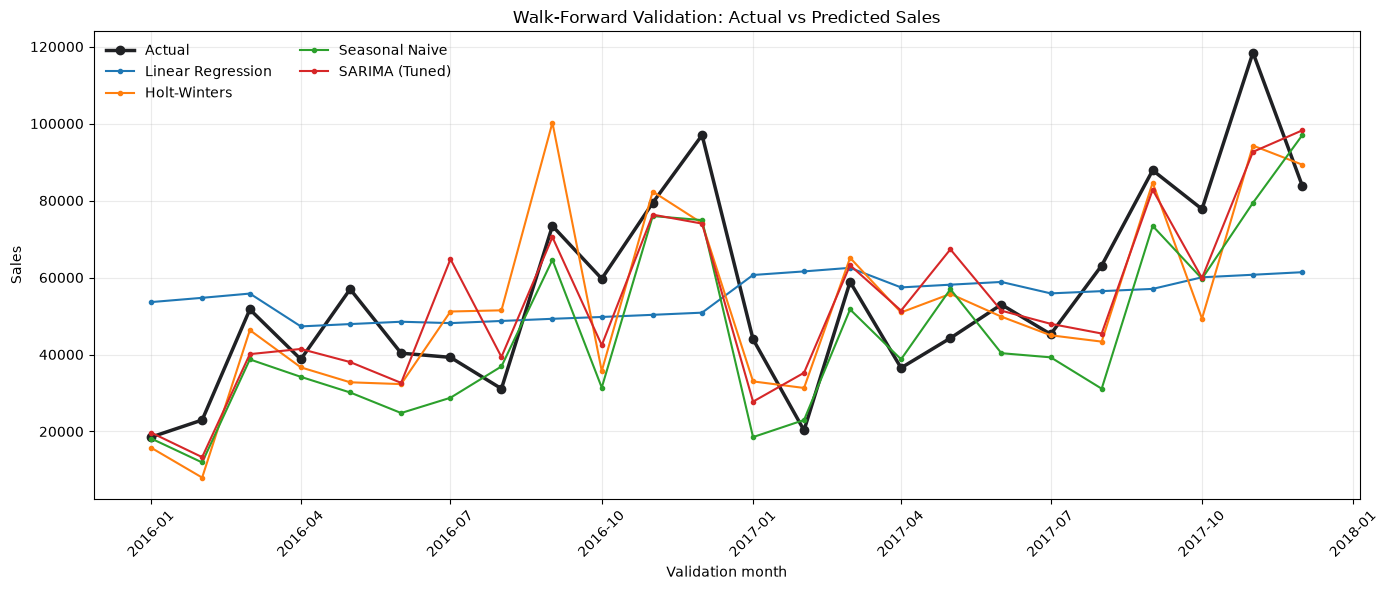

C:\Users\netsh\AppData\Local\Temp\ipykernel_18380\4165287833.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(walk_forward_comparison.sort_values("Absolute Error", ascending=False).head(8).round(2))


,Month,Actual Sales,Linear Regression,Holt-Winters,Seasonal Naive,SARIMA (Tuned),Best Model,Absolute Error
22,2017-11-01,118447.82,60723.49,94279.82,79411.97,92657.81,92657.81,25790.02
6,2016-07-01,39261.96,48156.70,51172.37,28765.32,64779.60,64779.60,25517.64
16,2017-05-01,44261.11,58142.65,55749.12,56987.73,67331.97,67331.97,23070.86
11,2016-12-01,96999.04,50871.78,74115.56,74919.52,74014.96,74014.96,22984.09
4,2016-05-01,56987.73,47907.89,32780.78,30131.69,38037.61,38037.61,18950.12
21,2017-10-01,77776.92,60061.07,49322.46,59687.74,59863.68,59863.68,17913.25
19,2017-08-01,63120.89,56464.09,43348.67,31115.37,45452.21,45452.21,17668.68
9,2016-10-01,59687.74,49752.54,35714.11,31404.92,42425.06,42425.06,17262.68


Across the shared validation months, SARIMA (Tuned) had MAE 12,098.59, RMSE 14,461.16, and MAPE 24.89%.


In [31]:
walk_forward_comparison = pd.DataFrame({
    "Month": comparison_months,
    "Actual Sales": comparison_actual,
    **model_predictions,
})

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(walk_forward_comparison["Month"], walk_forward_comparison["Actual Sales"], color="#202124", marker="o", linewidth=2.5, label="Actual")
for model_name in model_predictions:
    ax.plot(walk_forward_comparison["Month"], walk_forward_comparison[model_name], marker=".", linewidth=1.5, label=model_name)
ax.set_title("Walk-Forward Validation: Actual vs Predicted Sales")
ax.set_xlabel("Validation month")
ax.set_ylabel("Sales")
ax.legend(ncol=2, frameon=False)
ax.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

walk_forward_comparison["Best Model"] = walk_forward_comparison[best_model_walk]
walk_forward_comparison["Absolute Error"] = (walk_forward_comparison["Actual Sales"] - walk_forward_comparison["Best Model"]).abs()
display(walk_forward_comparison.sort_values("Absolute Error", ascending=False).head(8).round(2))

best_model_metrics = model_comparison.set_index("Model").loc[best_model_walk]
print(f"Across the shared validation months, {best_model_walk} had MAE {best_model_metrics['MAE']:,.2f}, RMSE {best_model_metrics['RMSE']:,.2f}, and MAPE {best_model_metrics['MAPE']:.2f}%.")


c:\Users\netsh\OneDrive\Documentos\Moose CODES\FUTURE_ML_01\SuperStore\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


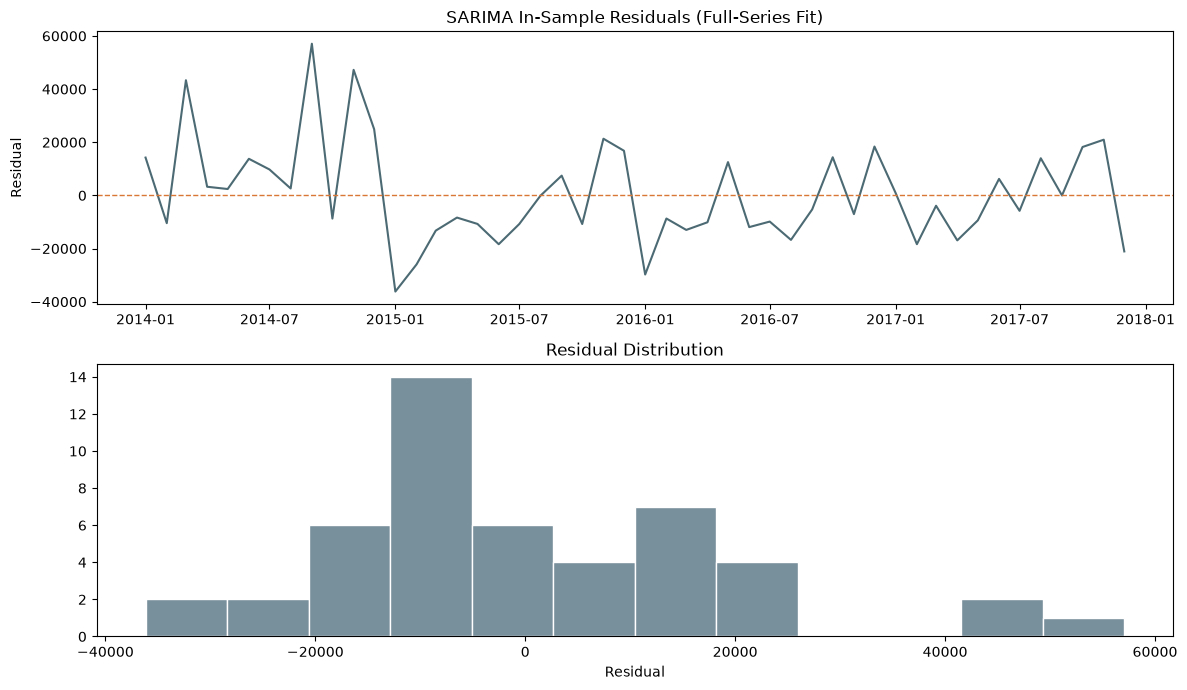

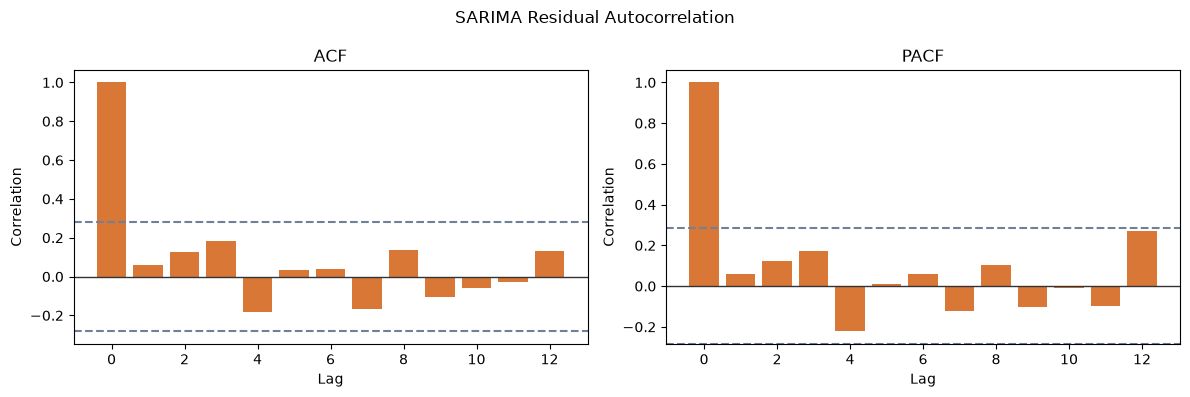

,lb_stat,lb_pvalue
12,9.643257,0.290962


Ljung–Box p-value = 0.2910: insufficient evidence of residual autocorrelation at the 5% level.


In [32]:
final_sarima_model = SARIMAX(
    sales,
    order=best_sarima_config["order"],
    seasonal_order=best_sarima_config["seasonal_order"],
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False, maxiter=200)
joblib.dump(final_sarima_model, models_dir / "sarima_model.pkl")

sarima_residuals = pd.Series(final_sarima_model.resid).replace([np.inf, -np.inf], np.nan).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(monthly_sales["Order Date"].iloc[-len(sarima_residuals):], sarima_residuals, color="#4C6A73")
axes[0].axhline(0, color="#D97736", linestyle="--", linewidth=1)
axes[0].set_title("SARIMA In-Sample Residuals (Full-Series Fit)")
axes[0].set_ylabel("Residual")
axes[1].hist(sarima_residuals, bins=12, color="#78909C", edgecolor="white")
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")
fig.tight_layout()
plt.show()

diagnostic_lags = min(12, len(sarima_residuals) // 2 - 1)
if diagnostic_lags >= 1:
    acf_values = acf(sarima_residuals, nlags=diagnostic_lags, fft=False)
    pacf_values = pacf(sarima_residuals, nlags=diagnostic_lags, method="ywm")
    confidence_limit = 1.96 / np.sqrt(len(sarima_residuals))
    diagnostic_fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for axis, values, title in zip(axes, [acf_values, pacf_values], ["ACF", "PACF"]):
        axis.bar(range(len(values)), values, color="#D97736")
        axis.axhline(0, color="#333333", linewidth=1)
        axis.axhline(confidence_limit, color="#718096", linestyle="--")
        axis.axhline(-confidence_limit, color="#718096", linestyle="--")
        axis.set(title=title, xlabel="Lag", ylabel="Correlation")
    diagnostic_fig.suptitle("SARIMA Residual Autocorrelation")
    diagnostic_fig.tight_layout()
    plt.show()

    model_df = (
        best_sarima_config["order"][0]
        + best_sarima_config["order"][2]
        + best_sarima_config["seasonal_order"][0]
        + best_sarima_config["seasonal_order"][2]
    )
    if diagnostic_lags > model_df:
        ljung_box = acorr_ljungbox(
            sarima_residuals,
            lags=[diagnostic_lags],
            model_df=model_df,
            return_df=True,
        )
        display(ljung_box)
        p_value = ljung_box["lb_pvalue"].iloc[0]
        if p_value < 0.05:
            print(f"Ljung–Box p-value = {p_value:.4f}: evidence of remaining residual autocorrelation at the 5% level.")
        else:
            print(f"Ljung–Box p-value = {p_value:.4f}: insufficient evidence of residual autocorrelation at the 5% level.")
    else:
        print(f"Ljung–Box test not reported: {diagnostic_lags} usable lags do not exceed model_df={model_df}.")
else:
    print("Not enough residual observations for ACF, PACF, or Ljung–Box diagnostics.")
